In [3]:
import pandas as pd, numpy as np, re
import matplotlib.pyplot as plt, seaborn as sns

df = pd.read_csv("data/youtube_comments_raw.csv")
print("Shape:", df.shape)

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 250)
pd.set_option("display.max_rows", 100)
vids = df.drop_duplicates("video_id")[["brand", "video_title", "channel_title"]]
vids.sort_values("brand")

Shape: (2000, 14)


,brand,video_title,channel_title
1990,Alkaram Studio,Alkaram Winter Collection 2021 || Shawl Suits || Alkaram New Arrival,Umme Abiya
1898,Alkaram Studio,AlKaram Studio Sale on Eid Festive Summer Collection 20 | Shop Online Lawn Shirts Pric...,Rabia Khan
1838,Alkaram Studio,Alkaram Studio Eid Bazaar || Alkaram Studio Sale 2021 ||,Kanwal Rohail
1778,Alkaram Studio,Summer Shopping Haul from Alkram Studio||Alkaram Studio Catalyst||Alkaram Studio Unboxing,Vlogs for all
1720,Alkaram Studio,Alkaram Studio 50% Sale 2019 - Shopping Haul by Fizza Style,Fizza Style
1660,Alkaram Studio,Hira Mani's Shopping At - Alkaram Studio,Alkaram
1600,Alkaram Studio,#AyezaKhan - Alkaram Mann Moriya - Spring Summer Lawn Collection 2018,Alkaram
1930,Alkaram Studio,"ALKARAM Studio 3 piece Lawn Duppata | Super Wholesale Price in Faisalabad Pakistan 2021""",Market Boy
760,Gul Ahmed,J. SALE FLAT 25% OFF & GUL AHMED SHOPPING HAUL- lock down -Vlogs for all,Vlogs for all
700,Gul Ahmed,"Gul Ahmed chunri suits.2020 new collection.with price , Yusra Boutique",yusra boutique


In [4]:
# ===== galat videos ke titles ke lafz (chhote haroof mein) =====
EXTRA_REMOVE = [
    "huge clothing",        # Khaadi ki 2 multi-brand videos
    "limelight",            # J. + Khaadi + Limelight wali
    "j. sale flat 25%",     # Gul Ahmed + J. mix
    "miniso",               # Sapphire wali Rs 15,000 haul
    "cutting and stitching" # Sapphire tailoring tutorial
]

other_brand_words = {
    "Khaadi": ["khaadi", "khaddi"],
    "Gul Ahmed": ["gul ahmed", "gulahmed"],
    "Sapphire": ["sapphire"],
    "J. Junaid Jamshed": ["junaid jamshed"],
    "Alkaram Studio": ["alkaram", "alkram", "al karam"],
}

def mentions_other_brand(row):
    t = str(row["video_title"]).lower()
    for b, words in other_brand_words.items():
        if b != row["brand"] and any(w in t for w in words):
            return True
    return False

mix_mask = df.apply(mentions_other_brand, axis=1)
remove_words = ["k-pop", "kpop", "demon hunters"] + EXTRA_REMOVE
bad_mask = df["video_title"].str.lower().apply(lambda t: any(w in t for w in remove_words))

print("Multi-brand comments hat gaye:", mix_mask.sum())
print("Unrelated comments hat gaye  :", bad_mask.sum())
df = df[~mix_mask & ~bad_mask].copy()

# Basic cleaning
df = df.dropna(subset=["comment_text"])
df = df.drop_duplicates(subset=["video_id", "comment_text"])

def clean_comment(t):
    t = str(t).lower()
    t = re.sub(r"http\S+", "", t)
    t = re.sub(r"\s+", " ", t).strip()
    return t

df["clean_comment"] = df["comment_text"].apply(clean_comment)
df = df[df["clean_comment"].str.len() > 1]

df.to_csv("data/youtube_cleaned.csv", index=False)
print("\nCleaned shape:", df.shape)
print(df.groupby("brand").size())
print("\nBachi hui videos:", df["video_id"].nunique())

Multi-brand comments hat gaye: 220
Unrelated comments hat gaye  : 480

Cleaned shape: (1455, 15)
brand
Alkaram Studio       397
Gul Ahmed            360
J. Junaid Jamshed    338
Khaadi               240
Sapphire             120
dtype: int64

Bachi hui videos: 26


In [5]:
import pandas as pd, re

base = pd.read_csv("data/youtube_cleaned.csv")        # purana saaf data (1455)
extra = pd.read_csv("data/youtube_comments_extra.csv")

# sirf Khaadi, aur interview wali video hatao
extra = extra[extra["brand"] == "Khaadi"]
extra = extra[~extra["video_title"].str.lower().str.contains("shamoon sultan")].copy()

# wohi cleaning
extra = extra.dropna(subset=["comment_text"])
extra = extra.drop_duplicates(subset=["video_id", "comment_text"])

def clean_comment(t):
    t = str(t).lower()
    t = re.sub(r"http\S+", "", t)
    return re.sub(r"\s+", " ", t).strip()

extra["clean_comment"] = extra["comment_text"].apply(clean_comment)
extra = extra[extra["clean_comment"].str.len() > 1]

df = pd.concat([base, extra], ignore_index=True)
df = df.drop_duplicates(subset=["video_id", "comment_text"])
df.to_csv("data/youtube_cleaned.csv", index=False)

print("Total:", df.shape)
print(df.groupby("brand").size())
print("Videos:", df["video_id"].nunique())

Total: (1572, 15)
brand
Alkaram Studio       397
Gul Ahmed            360
J. Junaid Jamshed    338
Khaadi               357
Sapphire             120
dtype: int64
Videos: 29


In [6]:
import pandas as pd

df = pd.read_csv("data/youtube_sentiment.csv")
print(df.shape)

parts = []
for lang, n in [("English/Other", 25), ("Roman Urdu", 25), ("Urdu script", 10)]:
    sub = df[df["language"] == lang]
    parts.append(sub.sample(min(n, len(sub)), random_state=42))

sample = pd.concat(parts)[["language", "comment_text"]].copy()
sample = sample.reset_index().rename(columns={"index": "row_id"})
sample["my_label"] = ""     # model ka jawab jaan boojh ke chhupa diya
sample.to_csv("data/manual_label_sample.csv", index=False, encoding="utf-8-sig")
print("Saved:", len(sample), "comments")

(1572, 18)
Saved: 60 comments


In [7]:
import pandas as pd, numpy as np, re

base = pd.read_csv("data/youtube_cleaned.csv")
base.to_csv("data/youtube_cleaned_backup_1572.csv", index=False)   # backup
new = pd.read_csv("data/youtube_comments_sapphire.csv")
new = new[~new["video_title"].str.lower().str.contains("image batik")].copy()

def clean_comment(t):
    t = str(t).lower()
    t = re.sub(r"http\S+", "", t)
    return re.sub(r"\s+", " ", t).strip()

new = new.dropna(subset=["comment_text"])
new["clean_comment"] = new["comment_text"].apply(clean_comment)
new = new[new["clean_comment"].str.len() > 1]

df = pd.concat([base, new], ignore_index=True)
df = df.drop_duplicates(subset=["video_id", "comment_text"]).reset_index(drop=True)

# ===== LANGUAGE DETECTOR =====
RU = set("""hai hain hy hn nahi nahin nhi nai bohat bohot bahut buhat bht bhut boht acha achi achay
achy accha achhi achha aap ap apki apka apke aapki aapka aapke apni apna kya kia kiya kaisa kaisi
kaise kese kahan kahaan kab kyun kyu kiun liye lye ke ka ki ko mein mei pe se ye yeh wo woh yahan
wahan tha thi thay bhi aur lekin magar jo jis jab kitne kitna kitni mujhe mujhy mjhe mera meri
mere hum hamare tum tumhari sab sub bhai behan baji api apa allah mashallah mashaallah masha
ameen amin shukriya shukria bilkul zabardast khubsurat khoobsurat behtareen pasand lagta lagti
lagi laga rahi raha rahe kar karo kare karen karna krna karti karta kiye dena dain wala wali wale
sath saath baat kuch koi kon kaun kis kisi abhi phir agar toh tou mat bas chahiye chaye chahye
milta milti nazar dekh dekha dekho dekhna hamesha humesha waisy waise aisa aisi aise itna itni
itne kam zyada sasta sasti sastay mehnga mehngi dukaan jaldi shayad sirf wahi yahi unka unki unke
ham tumhein aapko apko ne hoga hogi gaya gayi gaye hota hoti hote hon hun hoon thanx dua duaon
naseeb salam assalam walaikum aoa subhanallah alhamdulillah allhamdulillah""".split())

EN = set("""the a an and or but is are was were be been am i you he she it we they me my your his her
our their this that these those of in on at to for with from by as so very too not no yes please
plz thank thanks love nice good great best beautiful pretty amazing awesome wow gorgeous lovely
cute dress dresses suit suits video videos vlog shopping shop sale price prices collection color
colour colours quality fabric brand song music voice look looks looking like want need how what
where when which who why can will would should could do does did have has had just also more most
all any some one two three first last new old much many really super sister brother madam sir dear
watch watching subscribe subscriber keep up effort job doing home online order available deliver
delivery store outlet cheap expensive worth""".split())

def detect_language(text):
    t = str(text)
    arabic = len(re.findall(r"[\u0600-\u06FF]", t))
    latin = len(re.findall(r"[A-Za-z]", t))
    if arabic + latin == 0:
        return "Emoji/Other"
    if arabic > 0:
        return "Urdu script" if arabic >= latin else "Mixed"
    words = re.findall(r"[a-z]+", t.lower())
    ru = sum(w in RU for w in words)
    en = sum(w in EN for w in words)
    if ru == 0:
        return "English"
    if en == 0:
        return "Roman Urdu"
    share = ru / (ru + en)
    if share >= 0.6: return "Roman Urdu"
    if share <= 0.25: return "English"
    return "Mixed"

df["language"] = df["clean_comment"].apply(detect_language)

# ===== TOPIC TAGS =====
TOPICS = [
    ("Music/Song", ["song", "music", "voice", "singer", "sing", "track", "lyrics", "gana", "gaana",
                    "awaz", "ghazal", "composition", "soundtrack", "ost", "گانا", "آواز"]),
    ("Price/Sale", ["price", "prices", "rate", "rates", "sale", "discount", "off", "sasta", "sastay",
                    "sasti", "mehnga", "mehngi", "cost", "qeemat", "kitne", "kitna", "rs", "rupees",
                    "expensive", "cheap", "affordable", "قیمت"]),
    ("Order/Availability", ["order", "available", "availability", "delivery", "deliver", "link",
                            "address", "branch", "store", "outlet", "whatsapp", "whatsup", "number",
                            "contact", "stock", "online", "kahan", "where"]),
    ("Product/Style", ["dress", "dresses", "suit", "suits", "colour", "color", "print", "prints",
                       "design", "designs", "fabric", "lawn", "collection", "shirt", "dupatta",
                       "duppata", "chunri", "trouser", "stitched", "quality", "look", "looks"]),
    ("Praise/Dua", ["mashallah", "mashaallah", "masha", "allah", "ameen", "amin", "dua", "duaon",
                    "bless", "god", "love", "beautiful", "pretty", "gorgeous", "amazing", "nice",
                    "wow", "ماشاء", "اللہ", "آمین", "زبردست"]),
]

def get_topic(text):
    t = str(text).lower()
    words = set(re.findall(r"[a-z]+", t))
    for topic, keys in TOPICS:
        for k in keys:
            if (k.isascii() and k in words) or (not k.isascii() and k in t):
                return topic
    return "Other"

df["topic"] = df["clean_comment"].apply(get_topic)

# ===== Time aur engagement =====
df["published"] = pd.to_datetime(df["published_utc"]) + pd.Timedelta(hours=5)
df["day"] = df["published"].dt.day_name()
df["hour"] = df["published"].dt.hour
df["engagement"] = df["likes"] + df["comments_count"]
df["engagement_rate"] = df["engagement"] / df["views"].replace(0, np.nan) * 100

df.to_csv("data/youtube_cleaned.csv", index=False)

# ===== CHECKS =====
print("Total:", df.shape)
print(df.groupby("brand").size(), "\n")
print("Videos:", df["video_id"].nunique(), "\n")
print(df["language"].value_counts(), "\n")
print(df["topic"].value_counts(), "\n")
print("Music wale comments kin videos se aaye:")
print(df[df["topic"] == "Music/Song"].groupby(["brand", "video_title"]).size().sort_values(ascending=False).head(8), "\n")
for lang in ["Roman Urdu", "English", "Mixed"]:
    s = df[df["language"] == lang]["comment_text"]
    print(f"--- {lang} ke 8 random comments ---")
    for c in s.sample(min(8, len(s)), random_state=1):
        print("  *", c[:80])

Total: (1794, 22)
brand
Alkaram Studio       397
Gul Ahmed            360
J. Junaid Jamshed    338
Khaadi               357
Sapphire             342
dtype: int64 

Videos: 35 

language
English        1202
Roman Urdu      369
Mixed           180
Emoji/Other      28
Urdu script      15
Name: count, dtype: int64 

topic
Other                 709
Praise/Dua            447
Product/Style         326
Music/Song            149
Price/Sale             95
Order/Availability     68
Name: count, dtype: int64 

Music wale comments kin videos se aaye:
brand           video_title                                                          
Gul Ahmed       Gul Ahmed Summer Lawn Collection 2019                                    56
                #PakistanKiPehchan GulAhmed Summer Lawn Collection 2020                  45
                GulAhmed Summer Lawn 2021                                                39
Alkaram Studio  #AyezaKhan - Alkaram Mann Moriya - Spring Summer Lawn Collection 2018     8
Sa

In [8]:
import pandas as pd
df = pd.read_csv("data/youtube_cleaned.csv")

print("Music wale comments kin videos se aaye:")
t = df[df["topic"] == "Music/Song"].copy()
t["title"] = t["video_title"].str[:60]
print(t.groupby(["brand", "title"]).size().sort_values(ascending=False).head(8).to_string())

print("\n20 random 'English' comments (koi Roman Urdu to nahi?):")
for c in df[df["language"] == "English"]["comment_text"].sample(20, random_state=7):
    print("  *", c[:70])

Music wale comments kin videos se aaye:
brand           title                                                       
Gul Ahmed       Gul Ahmed Summer Lawn Collection 2019                           56
                #PakistanKiPehchan GulAhmed Summer Lawn Collection 2020         45
                GulAhmed Summer Lawn 2021                                       39
Alkaram Studio  #AyezaKhan - Alkaram Mann Moriya - Spring Summer Lawn Collec     8
Sapphire        TRY-ON HAUL!! with SKYE | Sapphire                               1

20 random 'English' comments (koi Roman Urdu to nahi?):
  * Mubarak ho dear❤❤❤❤
  * Hi heejrha changrhi
  * Awesome designs, 👏👏👏👏👏👏 Wonderful video. Thanks for sharing.
  * Very nice
  * All dresses are nice
  * waooo LOVE background music !!!!
  * last black n maroon very nice
  * Excellent sound track
  * Beautiful colours and prints of j,nice upload
  * I love almas clutches and shoes❤❤❤😍
  * i love u nisho api 😙😙..may Allah success u every field of life...wia

In [10]:
import os, glob, shutil, pandas as pd

print("Notebook yahan chal rahi hai:", os.getcwd())
print("data folder mein files:", os.listdir("data"))

downloads = os.path.join(os.path.expanduser("~"), "Downloads")
found = glob.glob(os.path.join(downloads, "youtube_sentiment*.csv"))
print("Downloads mein mili:", found)

if found:
    newest = max(found, key=os.path.getmtime)      # sab se nayi file
    shutil.copy(newest, "data/youtube_sentiment.csv")
    check = pd.read_csv("data/youtube_sentiment.csv")
    print("\nCopy ho gayi:", newest)
    print("Shape:", check.shape)
else:
    print("\nDownloads mein file nahi mili")

Notebook yahan chal rahi hai: c:\Users\Amna\Documents\Sentiment_analysis\social-media-sentiment-analysis
data folder mein files: ['manual_label_sample.csv', 'youtube_cleaned.csv', 'youtube_cleaned_backup_1572.csv', 'youtube_comments_extra.csv', 'youtube_comments_raw.csv', 'youtube_comments_sapphire.csv', 'youtube_sentiment .csv']
Downloads mein mili: ['C:\\Users\\Amna\\Downloads\\youtube_sentiment (1).csv', 'C:\\Users\\Amna\\Downloads\\youtube_sentiment.csv']

Copy ho gayi: C:\Users\Amna\Downloads\youtube_sentiment (1).csv
Shape: (1794, 24)


In [13]:
import pandas as pd

df = pd.read_csv("data/youtube_sentiment.csv")
print("Shape:", df.shape)          # (1794, 24) aana chahiye

# Bonus: har brand mein kitni language hai?
print(pd.crosstab(df["brand"], df["language"], normalize="index").round(2))

# 60 comments ka sample (model ka jawab chhupa hua)
parts = []
for lang, n in [("English", 20), ("Roman Urdu", 20), ("Mixed", 15), ("Urdu script", 5)]:
    sub = df[df["language"] == lang]
    parts.append(sub.sample(min(n, len(sub)), random_state=42))

sample = pd.concat(parts).sample(frac=1, random_state=1)      # mix kar do
sample = sample[["language", "comment_text"]].copy()
sample.insert(0, "row_id", sample.index)
sample["my_label"] = ""
sample.to_csv("data/manual_label_sample.csv", index=False, encoding="utf-8-sig")
print("Sample saved:", len(sample))

Shape: (1794, 24)
language           Emoji/Other  English  Mixed  Roman Urdu  Urdu script
brand                                                                  
Alkaram Studio            0.01     0.52   0.13        0.34         0.01
Gul Ahmed                 0.00     0.80   0.09        0.10         0.01
J. Junaid Jamshed         0.01     0.68   0.07        0.23         0.00
Khaadi                    0.01     0.70   0.09        0.19         0.01
Sapphire                  0.05     0.66   0.12        0.15         0.02
Sample saved: 60


In [14]:
df = pd.read_csv("data/youtube_sentiment.csv")
df["row_id"] = df.index

chk = pd.read_csv("data/manual_label_sample.csv")
chk["my_label"] = chk["my_label"].astype(str).str.strip().str.capitalize()
chk = chk[chk["my_label"].isin(["Positive", "Negative", "Neutral"])]
chk = chk.merge(df[["row_id", "sentiment"]], on="row_id")
chk["ok"] = chk["my_label"] == chk["sentiment"]

print("Labelled:", len(chk))
print("Overall accuracy:", round(chk["ok"].mean() * 100, 1), "%\n")
print(chk.groupby("language")["ok"].agg(accuracy="mean", count="count").round(2), "\n")
print(pd.crosstab(chk["my_label"], chk["sentiment"], rownames=["Meri label"], colnames=["Model"]))

Labelled: 60
Overall accuracy: 75.0 %

             accuracy  count
language                    
English          0.75     20
Mixed            0.67     15
Roman Urdu       0.80     20
Urdu script      0.80      5 

Model       Negative  Neutral  Positive
Meri label                             
Neutral            4       10         9
Positive           2        0        35


In [15]:
import pandas as pd, numpy as np

df = pd.read_csv("data/youtube_sentiment.csv")
df["row_id"] = df.index

chk = pd.read_csv("data/manual_label_sample.csv")
chk["my_label"] = chk["my_label"].astype(str).str.strip().str.capitalize()
chk = chk[chk["my_label"].isin(["Positive", "Negative", "Neutral"])]
chk = chk.merge(df[["row_id", "sentiment", "sent_score", "brand"]], on="row_id")
chk["ok"] = chk["my_label"] == chk["sentiment"]

print("=== 1) Model ki 15 ghaltiyan ===")
for _, r in chk[~chk["ok"]].iterrows():
    print(f"[Meri: {r['my_label']} | Model: {r['sentiment']} | score {r['sent_score']:.2f}] {str(r['comment_text'])[:90]}")

print("\n=== 2) Kya 'kam confidence = Neutral' rule madad karta hai? ===")
for th in [0.0, 0.3, 0.5, 0.7, 0.8]:
    pred = np.where(chk["sent_score"].abs() < th, "Neutral", chk["sentiment"])
    print(f"threshold {th}: accuracy {round((pred == chk['my_label']).mean() * 100, 1)}%")

print("\n=== 3) Model ke 'Negative' comments: kya ye sach mein shikayat hain? ===")
neg = df[df["sentiment"] == "Negative"]
print("Total Negative:", len(neg))
print(neg.groupby("brand").size().to_string())
alk = neg[neg["brand"] == "Alkaram Studio"]
oth = neg[neg["brand"] != "Alkaram Studio"]
for name, part, n in [("Alkaram", alk, 15), ("Baqi brands", oth, 10)]:
    print(f"\n--- {name} ke {n} negative comments ---")
    for _, r in part.sample(min(n, len(part)), random_state=3).iterrows():
        print(f"[{r['brand'][:8]} | {r['sent_score']:.2f}] {str(r['comment_text'])[:90]}")

=== 1) Model ki 15 ghaltiyan ===
[Meri: Neutral | Model: Negative | score -0.11] Please dhaky apni froks
[Meri: Neutral | Model: Negative | score -0.17] Purani video to nai
[Meri: Neutral | Model: Positive | score 0.35] yr mughay ye song bra psabd hai💖
[Meri: Neutral | Model: Positive | score 0.60] Omggg mil gaya songggg yaaay Here u go guys!!! Jao jee lo song!!! 😃
[Meri: Neutral | Model: Positive | score 0.67] Love you ayeza Khan😍😍😘😘💕💕
[Meri: Neutral | Model: Positive | score 0.04] jo jo mera comment like kry ga Allah pak usko kisi ka mohtaj na kry amen vlogs with khushi
[Meri: Neutral | Model: Negative | score -0.06] Thank God.......so called U tubers nhi bolliye.......
[Meri: Neutral | Model: Positive | score 0.60] I am in Love with the BG Song.......
[Meri: Neutral | Model: Negative | score -0.14] Ouffffff 😭😭 and please same Mobile but video quality apki itni achi Kesy h why not mine ha
[Meri: Positive | Model: Negative | score -0.20] Bhot LaJawob .Bhot khob
[Meri: Positive | Model

In [16]:
import pandas as pd, numpy as np

df = pd.read_csv("data/youtube_sentiment.csv")

# Ghalat spelling wali tareef ko Negative se Positive karna
PRAISE = ["zabar", "zabr", "lajaw", "khoob", "khob", "khub", "kamaal", "behtar",
          "pasand", "psand", "mashaa", "mashal", "shandar"]
NEGATION = ["nahi", "nahin", "nhi", "not ", "never", "bura", "kharab", "worst", "fraud", "fake"]

def final_sentiment(row):
    t = str(row["clean_comment"])
    if row["sentiment"] == "Negative":
        if any(p in t for p in PRAISE) and not any(n in t for n in NEGATION):
            return "Positive"
    return row["sentiment"]

df["sentiment_final"] = df.apply(final_sentiment, axis=1)

changed = df[df["sentiment"] != df["sentiment_final"]]
print("Badle huay comments:", len(changed))
for c in changed["comment_text"].head(25):
    print("  *", str(c)[:80])

# Accuracy: pehle aur baad
df["row_id"] = df.index
chk = pd.read_csv("data/manual_label_sample.csv")
chk["my_label"] = chk["my_label"].astype(str).str.strip().str.capitalize()
chk = chk[chk["my_label"].isin(["Positive", "Negative", "Neutral"])]
chk = chk.merge(df[["row_id", "sentiment", "sentiment_final"]], on="row_id")
print("\nAccuracy pehle:", round((chk["my_label"] == chk["sentiment"]).mean() * 100, 1), "%")
print("Accuracy baad :", round((chk["my_label"] == chk["sentiment_final"]).mean() * 100, 1), "%")

# Brand tables (Music/Song comments alag karke aur sab ke saath)
b = df[df["topic"] != "Music/Song"]
print("\n--- Brand-wise sentiment (Music/Song hata kar) ---")
print(pd.crosstab(b["brand"], b["sentiment_final"], normalize="index").round(2))
print("\n--- Brand-wise sentiment (sab comments) ---")
print(pd.crosstab(df["brand"], df["sentiment_final"], normalize="index").round(2))

df.drop(columns=["row_id"]).to_csv("data/youtube_final.csv", index=False)
print("\nSaved: data/youtube_final.csv", df.shape)

Badle huay comments: 16
  * mashaAllah zaberdust latary sale
  * Bhot LaJawob .Bhot khob
  * MashaAllha zabrdst suit hy
  * Lajawab mashaAllah bohat achey
  * Lajawab bahut khoob
  * Zabardust.
  * Bahot zabardust
  * Zabardst sis asa tu koi nai krta k bina profit k dy msha Allah.Allah pk ko apki 
  * Zabardast
  * Mujhy b dark clr pasand hi
  * zabardast
  * Mashallah
  * Zabardast
  * Zabrdast vedio...
  * MashAllah
  * MashAllah zaberdast

Accuracy pehle: 75.0 %
Accuracy baad : 78.3 %

--- Brand-wise sentiment (Music/Song hata kar) ---
sentiment_final    Negative  Neutral  Positive
brand                                         
Alkaram Studio         0.21     0.24      0.55
Gul Ahmed              0.10     0.21      0.69
J. Junaid Jamshed      0.04     0.09      0.87
Khaadi                 0.04     0.06      0.90
Sapphire               0.12     0.21      0.67

--- Brand-wise sentiment (sab comments) ---
sentiment_final    Negative  Neutral  Positive
brand                             

=== Videos ki type (brand x source) ===
source_type        Brand Official  Creator/Reviewer
brand                                              
Alkaram Studio                  2                 6
Gul Ahmed                       3                 3
J. Junaid Jamshed               0                 6
Khaadi                          0                 7
Sapphire                        1                 7 



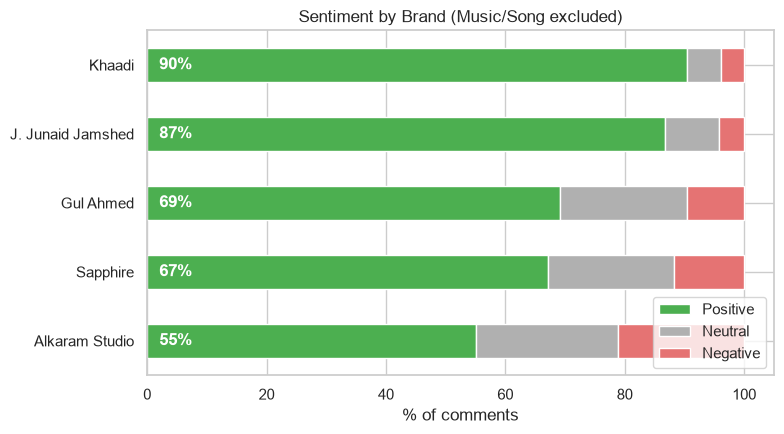

sentiment_final    Positive  Neutral  Negative
brand                                         
Khaadi                 90.0      6.0       4.0
J. Junaid Jamshed      87.0      9.0       4.0
Gul Ahmed              69.0     21.0      10.0
Sapphire               67.0     21.0      12.0
Alkaram Studio         55.0     24.0      21.0 



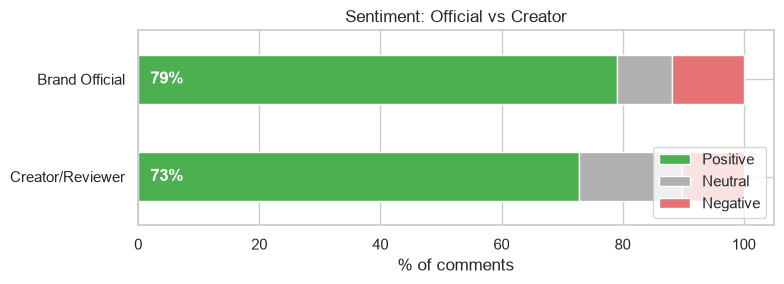

sentiment_final   Positive  Neutral  Negative
source_type                                  
Brand Official        79.0      9.0      12.0
Creator/Reviewer      73.0     17.0      10.0 



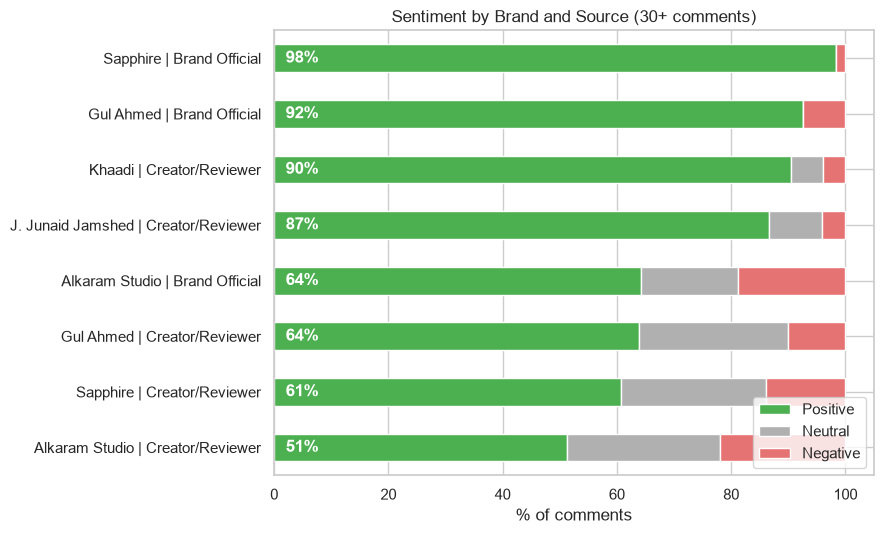

sentiment_final                       Positive  Neutral  Negative
group                                                            
Sapphire | Brand Official                 98.0      0.0       2.0
Gul Ahmed | Brand Official                92.0      0.0       8.0
Khaadi | Creator/Reviewer                 90.0      6.0       4.0
J. Junaid Jamshed | Creator/Reviewer      87.0      9.0       4.0
Alkaram Studio | Brand Official           64.0     17.0      19.0
Gul Ahmed | Creator/Reviewer              64.0     26.0      10.0
Sapphire | Creator/Reviewer               61.0     26.0      14.0
Alkaram Studio | Creator/Reviewer         51.0     27.0      22.0 

group
Khaadi | Creator/Reviewer               357
J. Junaid Jamshed | Creator/Reviewer    338
Sapphire | Creator/Reviewer             282
Alkaram Studio | Creator/Reviewer       277
Gul Ahmed | Creator/Reviewer            180
Alkaram Studio | Brand Official         112
Sapphire | Brand Official                59
Gul Ahmed | Brand Offici

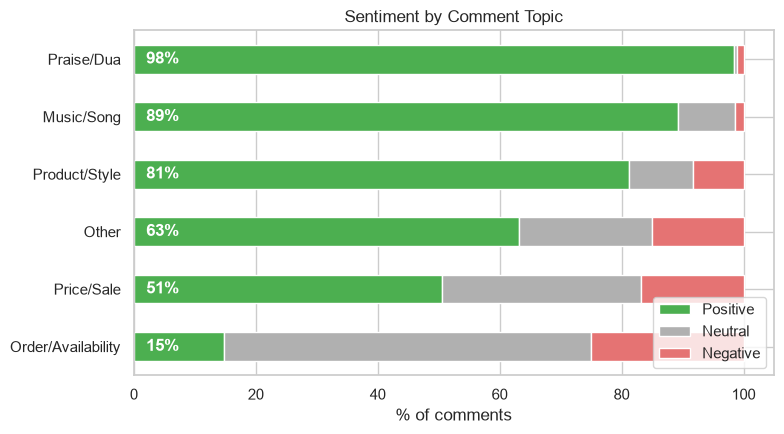

sentiment_final     Positive  Neutral  Negative
topic                                          
Praise/Dua              98.0      0.0       1.0
Music/Song              89.0      9.0       1.0
Product/Style           81.0     10.0       8.0
Other                   63.0     22.0      15.0
Price/Sale              51.0     33.0      17.0
Order/Availability      15.0     60.0      25.0 

=== Negative % ke hisaab se sab se mushkil 8 videos ===
         brand                                             video_title  comments  neg_pct  pos_pct
Alkaram Studio                Hira Mani's Shopping At - Alkaram Studio        60     32.0     40.0
      Sapphire Sapphire sale Pakistan 😂 #trendingshorts #ytshorts #for        48     31.0     15.0
Alkaram Studio ALKARAM Studio 3 piece Lawn Duppata | Super Wholesale P        59     31.0     34.0
      Sapphire     sapphire sale today / sapphire lawn collection 2024        49     29.0     16.0
Alkaram Studio Alkaram Studio 50% Sale 2019 - Shopping Haul by 

In [17]:
import pandas as pd, numpy as np, re, os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("outputs", exist_ok=True)
sns.set_theme(style="whitegrid")
df = pd.read_csv("data/youtube_final.csv")
vid = df.drop_duplicates("video_id").copy()      # video-level data

COLORS = {"Positive": "#4CAF50", "Neutral": "#B0B0B0", "Negative": "#E57373"}
ORDER = ["Positive", "Neutral", "Negative"]

def stacked(data, by, title, fname, figsize=(8, 4.5)):
    counts = pd.crosstab(data[by], data["sentiment_final"]).reindex(columns=ORDER, fill_value=0)
    t = counts.div(counts.sum(axis=1), axis=0) * 100
    t = t.sort_values("Positive", ascending=False)
    ax = t.plot(kind="barh", stacked=True, figsize=figsize, color=[COLORS[c] for c in ORDER])
    ax.invert_yaxis(); ax.set_xlabel("% of comments"); ax.set_ylabel(""); ax.set_title(title)
    for i, (idx, row) in enumerate(t.iterrows()):
        ax.text(2, i, f"{row['Positive']:.0f}%", va="center", color="white", fontweight="bold")
    plt.legend(loc="lower right"); plt.tight_layout()
    plt.savefig(f"outputs/{fname}.png", dpi=150, bbox_inches="tight"); plt.show()
    return t.round(0)

brand_df = df[df["topic"] != "Music/Song"].copy()

print("=== Videos ki type (brand x source) ===")
print(pd.crosstab(vid["brand"], vid["source_type"]), "\n")

print(stacked(brand_df, "brand", "Sentiment by Brand (Music/Song excluded)", "g1_sentiment_brand"), "\n")
print(stacked(brand_df, "source_type", "Sentiment: Official vs Creator", "g2_sentiment_source", (8, 3)), "\n")

brand_df["group"] = brand_df["brand"] + " | " + brand_df["source_type"]
cnt = brand_df["group"].value_counts()
keep = cnt[cnt >= 30].index
print(stacked(brand_df[brand_df["group"].isin(keep)], "group",
              "Sentiment by Brand and Source (30+ comments)", "g3_sentiment_brand_source", (9, 5.5)), "\n")
print(cnt.to_string(), "\n")

print(stacked(df, "topic", "Sentiment by Comment Topic", "g4_sentiment_topic"), "\n")

print("=== Negative % ke hisaab se sab se mushkil 8 videos ===")
vs = df.groupby(["brand", "video_title"]).agg(
    comments=("sentiment_final", "size"),
    neg_pct=("sentiment_final", lambda s: (s == "Negative").mean() * 100),
    pos_pct=("sentiment_final", lambda s: (s == "Positive").mean() * 100)).round(0).reset_index()
vs["video_title"] = vs["video_title"].str[:55]
print(vs.sort_values("neg_pct", ascending=False).head(8).to_string(index=False))

=== Engagement rate = (likes + comments) / views x 100, video level ===


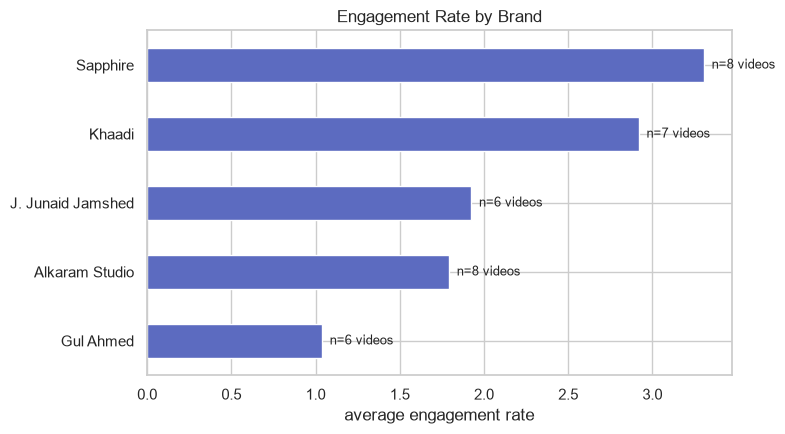

                   mean  n
brand                     
Gul Ahmed          1.04  6
Alkaram Studio     1.79  8
J. Junaid Jamshed  1.92  6
Khaadi             2.92  7
Sapphire           3.30  8 



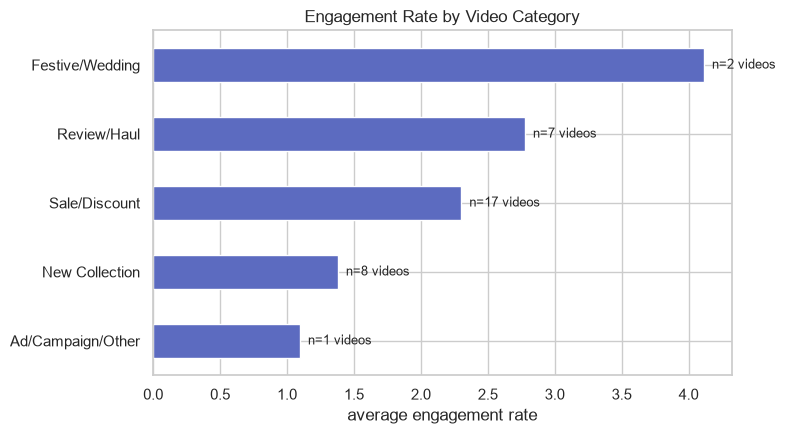

                   mean   n
video_category             
Ad/Campaign/Other  1.10   1
New Collection     1.38   8
Sale/Discount      2.30  17
Review/Haul        2.78   7
Festive/Wedding    4.11   2 



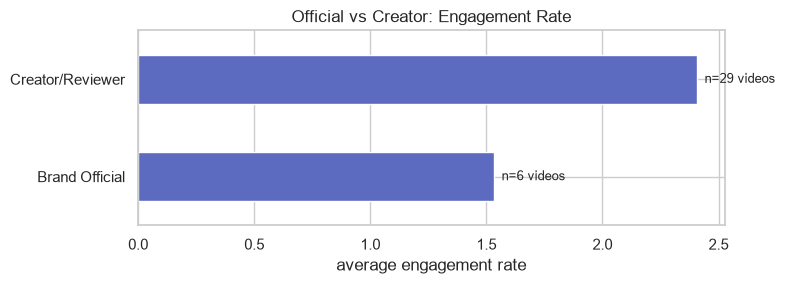

                  mean   n
source_type               
Brand Official    1.53   6
Creator/Reviewer  2.41  29 



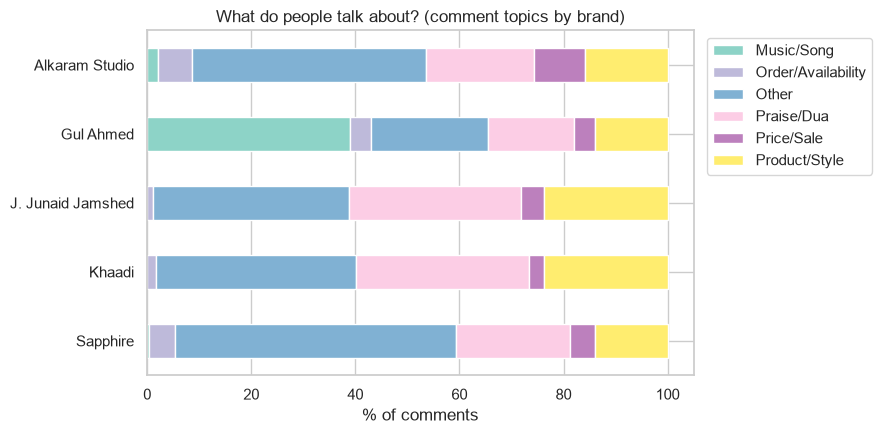

topic              Music/Song  Order/Availability  Other  Praise/Dua  Price/Sale  Product/Style
brand                                                                                          
Alkaram Studio              2                   7     45          21          10             16
Gul Ahmed                  39                   4     22          16           4             14
J. Junaid Jamshed           0                   1     38          33           4             24
Khaadi                      0                   2     38          33           3             24
Sapphire                    0                   5     54          22           5             14 



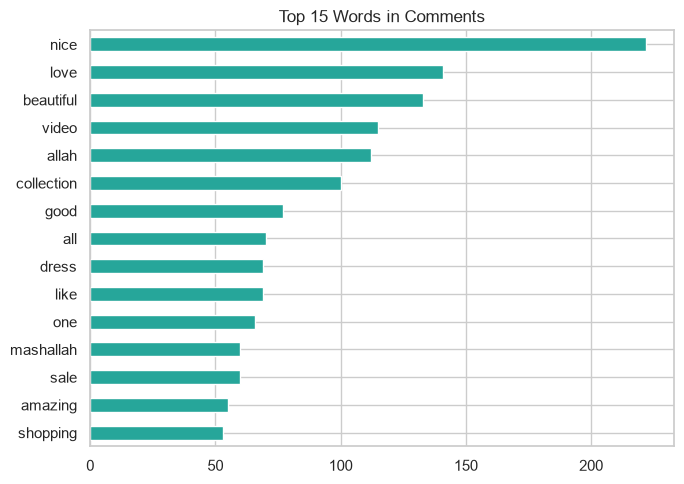

Top words: {'nice': 222, 'love': 141, 'beautiful': 133, 'video': 115, 'allah': 112, 'collection': 100, 'good': 77, 'all': 70, 'dress': 69, 'like': 69, 'one': 66, 'mashallah': 60, 'sale': 60, 'amazing': 55, 'shopping': 53} 

Top 10 emojis: [('❤', 482), ('😍', 253), ('👍', 124), ('👌', 93), ('🎉', 73), ('😂', 68), ('😘', 58), ('😊', 53), ('🥰', 47), ('💕', 32)]
Hashtags in titles: [('#pakistankipehchan', 1), ('#ayezakhan', 1), ('#trendingshorts', 1), ('#ytshorts', 1), ('#foryou', 1), ('#sapphire', 1), ('#sale', 1), ('#shopping', 1)]
Top video tag words: {'sale': 35, 'collection': 29, 'alkaram': 29, 'summer': 20, 'shopping': 17, '2019': 17, 'haul': 16, 'winter': 16, '2020': 16, 'khaadi': 15, 'sapphire': 15, 'studio': 15}


In [18]:
import pandas as pd, numpy as np, re, os
from collections import Counter
import matplotlib.pyplot as plt, seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("data/youtube_final.csv")
vid = df.drop_duplicates("video_id").copy()

def bar_with_n(data, by, col, title, fname, figsize=(8, 4.5)):
    g = data.groupby(by).agg(mean=(col, "mean"), n=("video_id", "count")).sort_values("mean")
    ax = g["mean"].plot(kind="barh", figsize=figsize, color="#5C6BC0")
    ax.set_title(title); ax.set_xlabel("average " + col.replace("_", " ")); ax.set_ylabel("")
    for i, (idx, r) in enumerate(g.iterrows()):
        ax.text(r["mean"], i, f"  n={int(r['n'])} videos", va="center", fontsize=9)
    plt.tight_layout(); plt.savefig(f"outputs/{fname}.png", dpi=150, bbox_inches="tight"); plt.show()
    return g.round(2)

print("=== Engagement rate = (likes + comments) / views x 100, video level ===")
print(bar_with_n(vid, "brand", "engagement_rate", "Engagement Rate by Brand", "g5_engagement_brand"), "\n")
print(bar_with_n(vid, "video_category", "engagement_rate", "Engagement Rate by Video Category", "g6_engagement_category"), "\n")
print(bar_with_n(vid, "source_type", "engagement_rate", "Official vs Creator: Engagement Rate", "g7_engagement_source", (8, 3)), "\n")

# Topics by brand
t = pd.crosstab(df["brand"], df["topic"], normalize="index") * 100
ax = t.plot(kind="barh", stacked=True, figsize=(9, 4.5), colormap="Set3")
ax.invert_yaxis(); ax.set_xlabel("% of comments"); ax.set_ylabel("")
ax.set_title("What do people talk about? (comment topics by brand)")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left"); plt.tight_layout()
plt.savefig("outputs/g8_topics_by_brand.png", dpi=150, bbox_inches="tight"); plt.show()
print(t.round(0).astype(int).to_string(), "\n")

# Top words (Music/Song hata kar)
STOP = set("""the a an and or but is are was were be been am i you he she it we they me my your his
her our their this that these those of in on at to for with from by as so very too not no yes please
plz thank thanks dear sis sister api apa ap aap apki apka apke hai hain hy hn ha ho hi ka ki ke ko se
me mein pe par ye yeh wo woh bhi aur kar kya nahi nhi bohat bht boht bahut tha thi hum mujhe mera meri
mere jo k n u ur r q""".split())
words = []
for c in df[df["topic"] != "Music/Song"]["clean_comment"]:
    words += [w for w in re.findall(r"[a-z]+", str(c)) if len(w) > 2 and w not in STOP]
top = pd.Series(Counter(words)).sort_values(ascending=False).head(15)
top.sort_values().plot(kind="barh", figsize=(7, 5), color="#26A69A", title="Top 15 Words in Comments")
plt.tight_layout(); plt.savefig("outputs/g9_top_words.png", dpi=150, bbox_inches="tight"); plt.show()
print("Top words:", top.to_dict(), "\n")

# Emojis aur hashtags (text mein, taake font ka masla na ho)
emo = Counter(re.findall(r"[\U0001F300-\U0001FAFF\u2600-\u27BF]", " ".join(df["comment_text"].astype(str))))
print("Top 10 emojis:", emo.most_common(10))
print("Hashtags in titles:", Counter(re.findall(r"#\w+", " ".join(vid["video_title"].astype(str)).lower())).most_common(10))
vt = vid["tags"].dropna().astype(str).str.lower().str.split().explode()
print("Top video tag words:", vt[vt.str.len() > 3].value_counts().head(12).to_dict())

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("data/youtube_final.csv")

# ---------- A) Video level ----------
v = df.groupby("video_id").agg(
    brand=("brand", "first"), source=("source_type", "first"),
    title=("video_title", lambda s: s.iloc[0][:35]),
    views=("views", "first"), eng_rate=("engagement_rate", "first"),
    n=("sentiment_final", "size"), avg_sent=("sent_score", "mean"),
    pos_pct=("sentiment_final", lambda s: (s == "Positive").mean() * 100),
    neg_pct=("sentiment_final", lambda s: (s == "Negative").mean() * 100),
).reset_index()
print("Videos:", len(v))

cols = ["brand", "source", "title", "views", "eng_rate", "pos_pct"]
print("\n--- Sab se zyada engagement rate wali 8 videos ---")
print(v.sort_values("eng_rate", ascending=False).head(8)[cols].round(1).to_string(index=False))
print("\n--- Sab se kam 5 ---")
print(v.sort_values("eng_rate").head(5)[cols].round(1).to_string(index=False))

print(f"\n=== Spearman correlation (n = {len(v)} videos) ===")
for col in ["avg_sent", "pos_pct", "neg_pct", "views"]:
    r = v[col].rank().corr(v["eng_rate"].rank())
    print(f"{col:9s} vs engagement rate: {r:.2f}")
print("(Is n par 0.35 se chhota number ka matlab: koi mazboot link nahi)")

plt.figure(figsize=(7, 4.5))
sns.scatterplot(data=v, x="pos_pct", y="eng_rate", hue="brand", s=90)
plt.xlabel("% positive comments (per video)"); plt.ylabel("Engagement rate (%)")
plt.title("Sentiment vs Engagement (each dot = 1 video)")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left"); plt.tight_layout()
plt.savefig("outputs/g10_sentiment_vs_engagement.png", dpi=150, bbox_inches="tight"); plt.show()

# ---------- B) Comment level: kaun se comments ko zyada likes milte hain ----------
for col in ["sentiment_final", "topic", "language"]:
    g = df.groupby(col)["comment_likes"].agg(mean="mean", median="median", n="size").round(1)
    print(f"\n=== Comment likes by {col} ===")
    print(g.sort_values("mean", ascending=False).to_string())

print("\n=== Sab se zyada liked 10 comments ===")
for _, r in df.sort_values("comment_likes", ascending=False).head(10).iterrows():
    print(f"[{r['comment_likes']} likes | {r['brand'][:8]} | {r['sentiment_final']}] {str(r['comment_text'])[:80]}")

Videos: 35

--- Sab se zyada engagement rate wali 8 videos ---
         brand           source                               title  views  eng_rate  pos_pct
      Sapphire Creator/Reviewer Sapphire Season Sale on Unstitched    6526       5.5     95.8
      Sapphire   Brand Official  TRY-ON HAUL!! with SKYE | Sapphire  27607       5.2     98.3
      Sapphire Creator/Reviewer Sapphire New Collection winter 2026   2319       5.2    100.0
        Khaadi Creator/Reviewer EID Haul & Look book with KHAADI! | 108648       4.8     98.3
      Sapphire Creator/Reviewer Sapphire Shopping Haul Flat 50% off 159574       4.5     86.7
Alkaram Studio Creator/Reviewer Summer Shopping Haul from Alkram St   5420       4.1     65.0
        Khaadi Creator/Reviewer Hurry Up!! | Prime Point - Mizaj -k  21855       3.7     95.0
        Khaadi Creator/Reviewer Khaadi Sale Haul || Huge summer kha  17426       3.7     79.5

--- Sab se kam 5 ---
            brand           source                               titl

ModuleNotFoundError: No module named 'scipy'